# Chemical space of Nigerian medicinal plant compounds

**Toyin Michael Onagoruwa** | November 2026

## Background

In 2018 I spent five months in four Hausa-Fulani communities in Lagos State documenting
medicinal plant use for my undergraduate thesis at the University of Lagos. I recorded 184
species, the parts used and how each remedy was prepared. The study ended with a question
fieldwork could not answer: what is actually inside these plants at the molecular level?

This notebook is a first computational pass at that question. It does **not** attempt to
predict biological activity or identify drug candidates. It asks a narrower, descriptive
question that public data can answer honestly:

> How structurally diverse are the compounds already catalogued from Nigerian medicinal
> plants, and how much of that chemical space is represented in the synthetic libraries
> that modern drug discovery screens against?

## Data

| Set | Source | Role |
|---|---|---|
| Nigerian medicinal plants | NMPP-DB v1.0 (Nigerian Medicinal Plants and Phytochemicals Database) | the set under study |
| Synthetic drug-like | 5,000-molecule random sample of ZINC 250k | reference for commercial screening space |
| Bioactive medicinal chemistry | ChEMBL EGFR compound set (via TeachOpenCADD) | reference for optimised medicinal chemistry |

The two reference sets are *comparators*, not targets. The EGFR set is used only because it
is a convenient, well-curated sample of compounds that medicinal chemists have actually
worked on; nothing here is screened against EGFR or any other protein.

## What this notebook does not do

No activity prediction, no docking, no therapeutic ranking and no claims about which
compounds might treat anything. Those questions need assay data, which is not what this
analysis has.

In [1]:
import os, sys, warnings
from pathlib import Path

# run from the repository root whether the notebook is launched from here or from notebooks/
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import chemspace as cs

SEED = cs.SEED
np.random.seed(SEED)

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("results"); RES.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"Nigerian medicinal plants": "#2E7D32",
           "ZINC synthetic drug-like": "#1565C0",
           "ChEMBL EGFR bioactives": "#EF6C00"}
ORDER = list(PALETTE)

print("pandas", pd.__version__)
import rdkit, sklearn
print("rdkit", rdkit.__version__, "| scikit-learn", sklearn.__version__)

pandas 3.0.5
rdkit 2026.09.1 | scikit-learn 1.9.1


## 1. Load and standardise

Every molecule is parsed with RDKit, reduced to its largest fragment (which strips salts and
co-crystallised solvents) and neutralised. Records that fail to parse and exact duplicate
structures are removed. The attrition table below is printed rather than hidden, because how
many records a cleaning step silently drops is part of the result.

In [2]:
nmpp_raw = cs.load_smi("data/raw/nmppdb.smi")
nmpp, audit_nmpp = cs.prepare(nmpp_raw, label="Nigerian medicinal plants")

zinc_raw = pd.read_csv("data/raw/zinc250k.csv")
zinc_raw["smiles"] = zinc_raw["smiles"].str.strip()
zinc_raw = zinc_raw.sample(5000, random_state=SEED)[["smiles"]]
zinc, audit_zinc = cs.prepare(zinc_raw, label="ZINC synthetic drug-like")

chembl_raw = pd.read_csv("data/raw/EGFR_compounds.csv")[["smiles"]]
chembl, audit_chembl = cs.prepare(chembl_raw, label="ChEMBL EGFR bioactives")

audit = pd.DataFrame([audit_nmpp, audit_zinc, audit_chembl]).set_index("set")
audit.to_csv(RES / "01_data_audit.csv")
audit

,input records,unparseable,duplicate structures,retained
set,,,,
Nigerian medicinal plants,1862,0,49,1813
ZINC synthetic drug-like,5000,0,0,5000
ChEMBL EGFR bioactives,5568,0,37,5531


## 2. Physicochemical descriptors

Ten standard descriptors plus stereocentre count and nitrogen/oxygen composition. Two of
these carry most of the signal when natural products are compared with synthetic libraries:

- **Fsp3**, the fraction of carbons that are sp3 hybridised, measures three-dimensionality.
  Flat aromatic molecules score near 0; saturated, three-dimensional ones near 1.
- **Stereocentres**, the number of defined or undefined chiral centres, measures how much
  stereochemical information a structure carries.

In [3]:
nmpp_d = cs.descriptor_table(nmpp)
zinc_d = cs.descriptor_table(zinc)
chembl_d = cs.descriptor_table(chembl)

desc_cols = list(cs.DESCRIPTORS) + ["Stereocentres", "N count", "O count"]
combined = pd.concat([nmpp_d, zinc_d, chembl_d], ignore_index=True)

summary = combined.groupby("set")[desc_cols].median().round(2).loc[ORDER]
summary.to_csv(RES / "02_descriptor_medians.csv")
summary.T

set,Nigerian medicinal plants,ZINC synthetic drug-like,ChEMBL EGFR bioactives
MW,222.26,335.41,442.98
cLogP,3.47,2.90,4.37
HBD,0.00,1.00,2.00
HBA,2.00,4.00,6.00
TPSA,26.30,63.99,88.15
RotB,3.00,5.00,6.00
Rings,1.00,3.00,4.00
AromaticRings,0.00,2.00,3.00
Fsp3,0.73,0.38,0.21
HeavyAtoms,16.00,23.00,31.00


### 2.1 Distribution comparison

Medians hide shape, so the distributions themselves are plotted. Axes are clipped at the
99th percentile of the pooled data so that a handful of very large molecules does not
compress everything else.

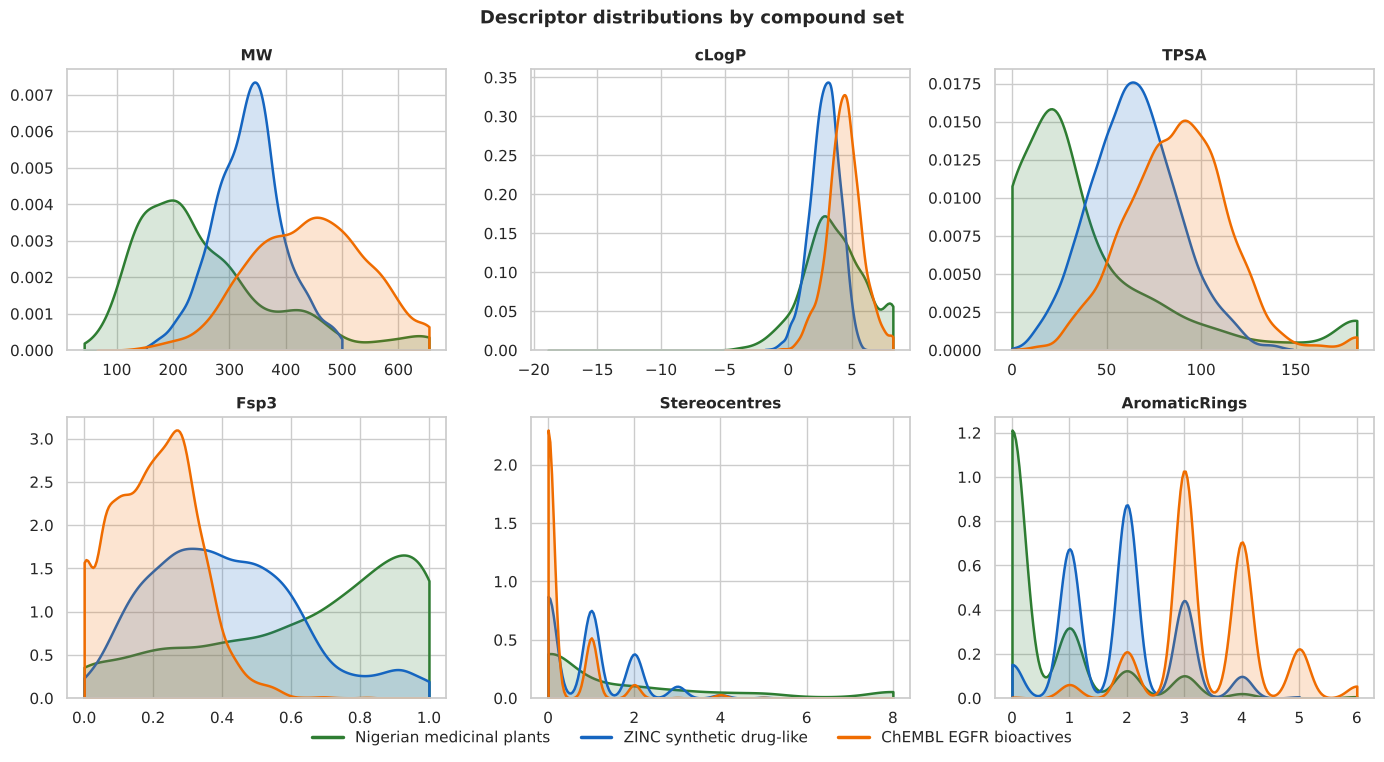

In [4]:
panel = ["MW", "cLogP", "TPSA", "Fsp3", "Stereocentres", "AromaticRings"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))

for ax, col in zip(axes.ravel(), panel):
    upper = combined[col].quantile(0.99)
    for name in ORDER:
        vals = combined.loc[combined["set"] == name, col]
        sns.kdeplot(vals.clip(upper=upper), ax=ax, label=name,
                    color=PALETTE[name], fill=True, alpha=0.18, linewidth=1.8, cut=0)
    ax.set_title(col, fontsize=11, weight="bold")
    ax.set_xlabel(""); ax.set_ylabel("")
    ax.get_legend().remove() if ax.get_legend() else None

handles = [plt.Line2D([], [], color=PALETTE[n], linewidth=2.5, label=n) for n in ORDER]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Descriptor distributions by compound set", fontsize=13, weight="bold")
fig.tight_layout()
fig.savefig(FIG / "01_descriptor_distributions.png", dpi=200, bbox_inches="tight")
plt.show()

### 2.2 The three-dimensionality signature

Fsp3 against stereocentre count separates the sets more cleanly than any single descriptor.
This reproduces a well-documented contrast between natural products and synthetic screening
libraries, on a collection that had not been profiled this way before.

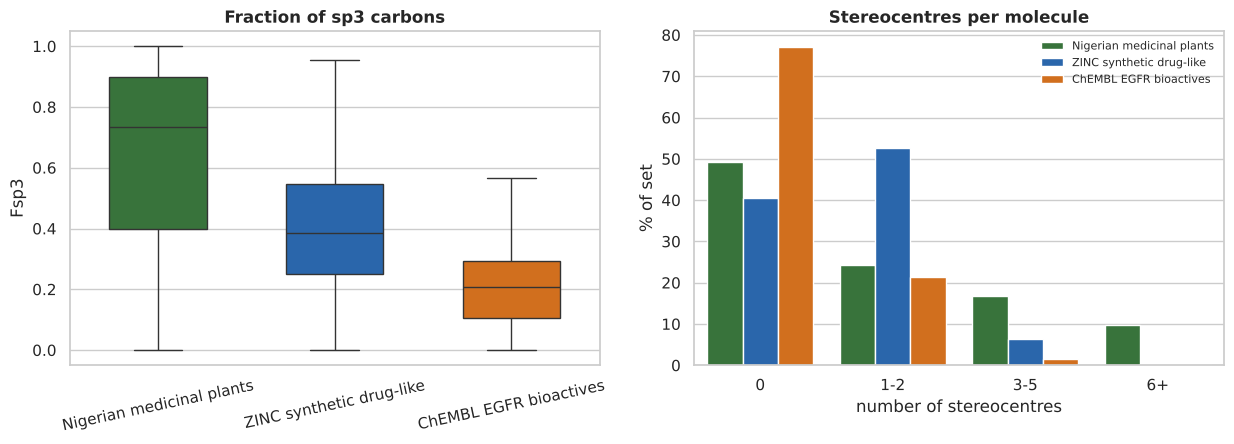

,median Fsp3,share with >=1 stereocentre
set,,
Nigerian medicinal plants,0.733,0.507
ZINC synthetic drug-like,0.385,0.594
ChEMBL EGFR bioactives,0.208,0.229


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))

sns.boxplot(data=combined, x="set", y="Fsp3", order=ORDER, ax=axes[0],
            palette=PALETTE, showfliers=False, width=0.55)
axes[0].set_title("Fraction of sp3 carbons", weight="bold")
axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=12)

buckets = pd.cut(combined["Stereocentres"], [-0.5, 0.5, 2.5, 5.5, np.inf],
                 labels=["0", "1-2", "3-5", "6+"])
stereo = (pd.crosstab(combined["set"], buckets, normalize="index")
          .mul(100).round(1).stack().rename("percent").reset_index())
stereo.columns = ["set", "bucket", "percent"]

sns.barplot(data=stereo, x="bucket", y="percent", hue="set", hue_order=ORDER,
            palette=PALETTE, ax=axes[1])
axes[1].set_title("Stereocentres per molecule", weight="bold")
axes[1].set_xlabel("number of stereocentres"); axes[1].set_ylabel("% of set")
axes[1].legend(frameon=False, fontsize=8)

fig.tight_layout()
fig.savefig(FIG / "02_three_dimensionality.png", dpi=200, bbox_inches="tight")
plt.show()

fsp3 = combined.groupby("set")["Fsp3"].median().loc[ORDER]
chiral = combined.assign(has=combined["Stereocentres"] > 0).groupby("set")["has"].mean().loc[ORDER]
pd.DataFrame({"median Fsp3": fsp3.round(3), "share with >=1 stereocentre": chiral.round(3)})

## 3. Rule-of-five profile

Lipinski's rule of five is a rough filter for orally available synthetic drugs. Natural
products break it routinely and remain orally active, so the counts below describe the
chemistry rather than judge it.

In [6]:
for frame in (nmpp_d, zinc_d, chembl_d):
    frame["Lipinski violations"] = frame.apply(cs.lipinski_violations, axis=1)

lip = pd.concat([nmpp_d, zinc_d, chembl_d], ignore_index=True)
lip_tab = (pd.crosstab(lip["set"], lip["Lipinski violations"], normalize="index")
           .mul(100).round(1).loc[ORDER])
lip_tab.columns = [f"{c} violation(s)" for c in lip_tab.columns]
lip_tab.to_csv(RES / "03_lipinski.csv")
lip_tab

,0 violation(s),1 violation(s),2 violation(s),3 violation(s),4 violation(s)
set,,,,,
Nigerian medicinal plants,66.5,27.2,3.3,3.0,0.0
ZINC synthetic drug-like,98.2,1.8,0.0,0.0,0.0
ChEMBL EGFR bioactives,55.3,28.7,15.6,0.4,0.0


## 4. Scaffold diversity

The Bemis-Murcko scaffold of a molecule is what remains after side chains are stripped: its
ring systems and the linkers between them. Counting unique scaffolds measures how much
structural variety a library holds, independently of how many compounds it contains.

In [7]:
for frame in (nmpp_d, zinc_d, chembl_d):
    frame["scaffold"] = frame["mol"].map(cs.murcko_scaffold)

rows, counts = {}, {}
for name, frame in zip(ORDER, (nmpp_d, zinc_d, chembl_d)):
    rows[name], counts[name] = cs.scaffold_summary(frame["scaffold"].tolist())

scaf = pd.DataFrame(rows).T.loc[ORDER]
scaf.to_csv(RES / "04_scaffold_diversity.csv")
scaf

,molecules,acyclic (no scaffold),unique scaffolds,scaffolds per 100 molecules,singleton scaffolds,share in singletons
Nigerian medicinal plants,1813.0,610.0,521.0,28.7,375.0,0.720
ZINC synthetic drug-like,5000.0,20.0,4116.0,82.3,3811.0,0.926
ChEMBL EGFR bioactives,5531.0,2.0,1864.0,33.7,1239.0,0.665


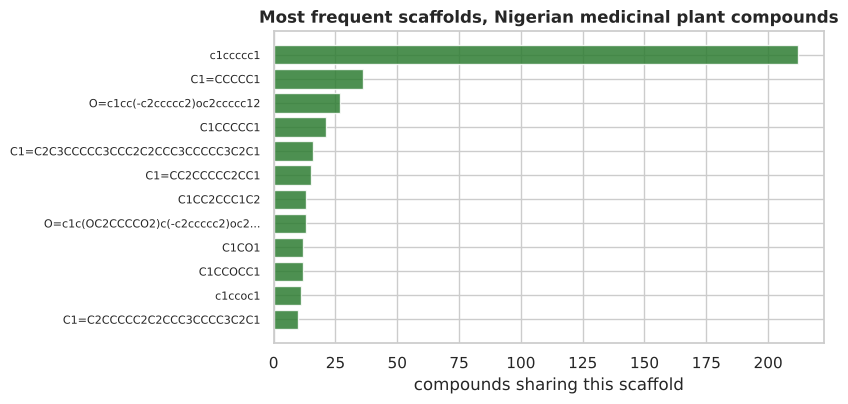

In [8]:
top = counts["Nigerian medicinal plants"].head(12)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.barh(range(len(top))[::-1], top.values, color="#2E7D32", alpha=0.85)
ax.set_yticks(range(len(top))[::-1])
ax.set_yticklabels([s if len(s) < 34 else s[:31] + "..." for s in top.index], fontsize=8)
ax.set_xlabel("compounds sharing this scaffold")
ax.set_title("Most frequent scaffolds, Nigerian medicinal plant compounds", weight="bold")
fig.tight_layout()
fig.savefig(FIG / "03_top_scaffolds.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Structural clustering

Butina clustering groups molecules whose Morgan fingerprints are at least 0.6 similar
(Tanimoto distance cut-off 0.4). The number of clusters relative to the number of compounds
is a second, fingerprint-based view of diversity: a library made of many near-duplicates
collapses into few clusters.

In [9]:
nmpp_fps = cs.fingerprints(nmpp_d["mol"])
assignment, clusters = cs.butina_clusters(nmpp_fps, cutoff=0.4)
nmpp_d["cluster"] = assignment

sizes = pd.Series([len(c) for c in clusters])
cluster_stats = pd.Series({
    "compounds": len(nmpp_fps),
    "clusters": len(clusters),
    "singletons": int((sizes == 1).sum()),
    "share in singletons": round(float((sizes == 1).sum() / len(clusters)), 3),
    "largest cluster": int(sizes.max()),
    "median cluster size": float(sizes.median()),
}, name="Butina, Tanimoto 0.6")
cluster_stats.to_frame().T.to_csv(RES / "05_clustering.csv", index=False)
cluster_stats

compounds              1813.000
clusters               1089.000
singletons              875.000
share in singletons       0.803
largest cluster          61.000
median cluster size       1.000
Name: Butina, Tanimoto 0.6, dtype: float64

## 6. Chemical space overlap

The question this notebook set out to ask. For each Nigerian plant compound, the Tanimoto
similarity to its single most similar molecule in each reference library is computed.

A low nearest-neighbour similarity means the reference library contains nothing structurally
close to that compound. By the usual medicinal chemistry convention, Tanimoto 0.85 on Morgan
fingerprints indicates near-identical structures and 0.4 indicates a loose resemblance.

In [10]:
zinc_fps = cs.fingerprints(zinc_d["mol"])
chembl_fps = cs.fingerprints(chembl_d["mol"])

nmpp_d["NN to ZINC"] = cs.nearest_neighbour_similarity(nmpp_fps, zinc_fps)
nmpp_d["NN to ChEMBL"] = cs.nearest_neighbour_similarity(nmpp_fps, chembl_fps)

overlap = pd.DataFrame({
    ref: {
        "median nearest-neighbour similarity": round(float(nmpp_d[ref].median()), 3),
        "% with no neighbour above 0.40": round(float((nmpp_d[ref] < 0.40).mean() * 100), 1),
        "% with no neighbour above 0.60": round(float((nmpp_d[ref] < 0.60).mean() * 100), 1),
        "% with a near-duplicate (>=0.85)": round(float((nmpp_d[ref] >= 0.85).mean() * 100), 1),
    } for ref in ["NN to ZINC", "NN to ChEMBL"]
})
overlap.to_csv(RES / "06_space_overlap.csv")
overlap

,NN to ZINC,NN to ChEMBL
median nearest-neighbour similarity,0.25,0.224
% with no neighbour above 0.40,95.60,90.300
% with no neighbour above 0.60,99.90,98.200
% with a near-duplicate (>=0.85),0.00,0.500


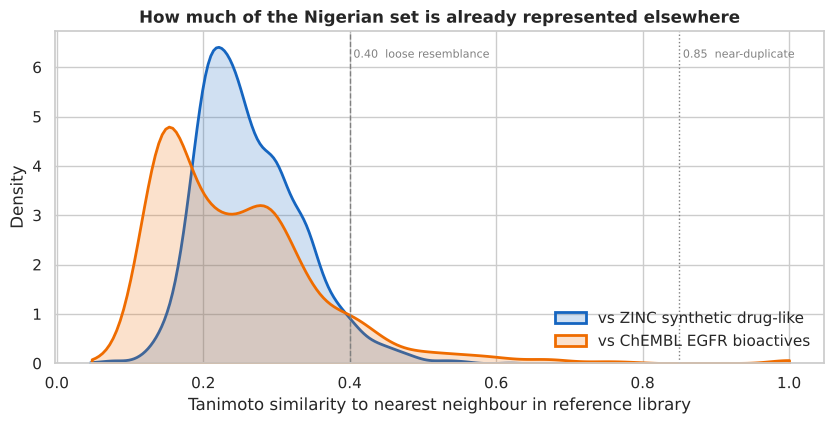

In [11]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for ref, colour, label in [("NN to ZINC", "#1565C0", "vs ZINC synthetic drug-like"),
                           ("NN to ChEMBL", "#EF6C00", "vs ChEMBL EGFR bioactives")]:
    sns.kdeplot(nmpp_d[ref], ax=ax, color=colour, fill=True, alpha=0.2,
                linewidth=2, label=label, cut=0)
ax.axvline(0.40, color="grey", linestyle="--", linewidth=1)
ax.axvline(0.85, color="grey", linestyle=":", linewidth=1)
ax.text(0.405, ax.get_ylim()[1] * 0.92, "0.40  loose resemblance", fontsize=8, color="grey")
ax.text(0.855, ax.get_ylim()[1] * 0.92, "0.85  near-duplicate", fontsize=8, color="grey")
ax.set_xlabel("Tanimoto similarity to nearest neighbour in reference library")
ax.set_title("How much of the Nigerian set is already represented elsewhere", weight="bold")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "04_space_overlap.png", dpi=200, bbox_inches="tight")
plt.show()

### 6.1 Sensitivity analysis: restricting by molecular weight

The Nigerian set is noticeably smaller and simpler than either reference library: its median
molecular weight is well below theirs and 610 of its 1,813 compounds have no ring system at
all. Fatty acids, simple terpenes and small sulfur compounds are abundant in it.

That is a confound. A short fatty acid has a high Fsp3 because it is an unbranched chain, not
because it is structurally interesting, and it may have no close neighbour in a drug-like
library simply because nobody stocks fatty acids. Before reading anything into the comparison,
the same analysis is repeated on the subset of each library that occupies comparable
drug-like territory: molecular weight between 250 and 600 Da with at least one ring.

This is a sensitivity analysis, not a matched design. The subsets are restricted to a shared
molecular weight window; their weight distributions within that window are not statistically
matched, so the test asks whether the findings survive the restriction rather than removing
size as a variable.

In [12]:
def drug_like_window(frame):
    return frame[(frame["MW"].between(250, 600)) & (frame["Rings"] >= 1)].copy()

nmpp_m = drug_like_window(nmpp_d)
zinc_m = drug_like_window(zinc_d)
chembl_m = drug_like_window(chembl_d)

retained = pd.DataFrame({
    "all compounds": [len(nmpp_d), len(zinc_d), len(chembl_d)],
    "within MW 250-600 and >=1 ring": [len(nmpp_m), len(zinc_m), len(chembl_m)],
}, index=ORDER)
retained["% retained"] = (100 * retained.iloc[:, 1] / retained.iloc[:, 0]).round(1)
retained

,all compounds,within MW 250-600 and >=1 ring,% retained
Nigerian medicinal plants,1813,434,23.9
ZINC synthetic drug-like,5000,4559,91.2
ChEMBL EGFR bioactives,5531,5061,91.5


In [13]:
zinc_m_fps = cs.fingerprints(zinc_m["mol"])
chembl_m_fps = cs.fingerprints(chembl_m["mol"])
nmpp_m_fps = cs.fingerprints(nmpp_m["mol"])

nmpp_m["NN to ZINC"] = cs.nearest_neighbour_similarity(nmpp_m_fps, zinc_m_fps)
nmpp_m["NN to ChEMBL"] = cs.nearest_neighbour_similarity(nmpp_m_fps, chembl_m_fps)

matched = pd.DataFrame({
    "all compounds": {
        "median Fsp3": round(float(nmpp_d["Fsp3"].median()), 3),
        "median stereocentres": float(nmpp_d["Stereocentres"].median()),
        "median NN similarity to ZINC": round(float(nmpp_d["NN to ZINC"].median()), 3),
        "% below 0.40 vs ZINC": round(float((nmpp_d["NN to ZINC"] < 0.40).mean() * 100), 1),
        "% below 0.40 vs ChEMBL": round(float((nmpp_d["NN to ChEMBL"] < 0.40).mean() * 100), 1),
    },
    "MW-restricted subset": {
        "median Fsp3": round(float(nmpp_m["Fsp3"].median()), 3),
        "median stereocentres": float(nmpp_m["Stereocentres"].median()),
        "median NN similarity to ZINC": round(float(nmpp_m["NN to ZINC"].median()), 3),
        "% below 0.40 vs ZINC": round(float((nmpp_m["NN to ZINC"] < 0.40).mean() * 100), 1),
        "% below 0.40 vs ChEMBL": round(float((nmpp_m["NN to ChEMBL"] < 0.40).mean() * 100), 1),
    },
})
matched["reference, restricted"] = [
    f"ZINC {zinc_m['Fsp3'].median():.3f} | ChEMBL {chembl_m['Fsp3'].median():.3f}",
    f"ZINC {zinc_m['Stereocentres'].median():.0f} | ChEMBL {chembl_m['Stereocentres'].median():.0f}",
    "", "", "",
]
matched.to_csv(RES / "06b_sensitivity_mw_restricted.csv")
matched

,all compounds,MW-restricted subset,"reference, restricted"
median Fsp3,0.733,0.50,ZINC 0.375 | ChEMBL 0.208
median stereocentres,1.000,3.00,ZINC 1 | ChEMBL 0
median NN similarity to ZINC,0.250,0.24,
% below 0.40 vs ZINC,95.600,97.70,
% below 0.40 vs ChEMBL,90.300,80.00,


The restriction changes two of the three findings, and it is worth being precise about how.

**Fsp3 weakens but holds.** The median drops from 0.73 to 0.50 once small acyclic compounds
are excluded, so part of the original gap was chain-like molecules rather than complex
three-dimensional scaffolds. The remaining gap against the restricted references is still
large.

**Stereochemistry strengthens.** The median stereocentre count rises from 1 to 3 in the
restricted subset, while both references stay at or near zero. The ring-bearing natural products
in this collection carry substantially more stereochemical information than drug-like
synthetic molecules of the same size.

**Structural novelty is unaffected.** The share of compounds with no neighbour above Tanimoto
0.40 in the ZINC sample barely moves. Against the ChEMBL bioactives it falls, which makes
sense: medicinal chemistry programmes have drawn on natural product scaffolds for decades, so
some of this chemistry has been visited before.

### 6.2 Projected chemical space

Principal component analysis of the fingerprint matrix gives a two-dimensional view of the
three libraries together. PCA on binary fingerprints captures only a small share of the total
variance, so this is an illustration of the overlap measured above, not evidence on its own.

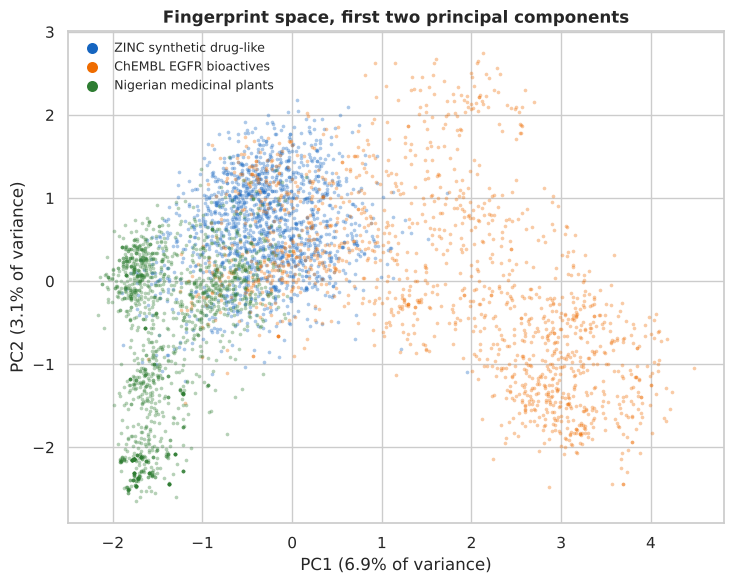

Variance captured by the two components shown: 10.0%


In [14]:
from sklearn.decomposition import PCA

sample_n = 1500
rng = np.random.default_rng(SEED)
parts, labels = [], []
for name, frame, fps in [("Nigerian medicinal plants", nmpp_d, nmpp_fps),
                         ("ZINC synthetic drug-like", zinc_d, zinc_fps),
                         ("ChEMBL EGFR bioactives", chembl_d, chembl_fps)]:
    idx = rng.choice(len(fps), size=min(sample_n, len(fps)), replace=False)
    parts.append(cs.fp_matrix([fps[i] for i in idx]))
    labels += [name] * len(idx)

X = np.vstack(parts)
pca = PCA(n_components=2, random_state=SEED).fit(X)
coords = pca.transform(X)

fig, ax = plt.subplots(figsize=(7.5, 6))
for name in ["ZINC synthetic drug-like", "ChEMBL EGFR bioactives", "Nigerian medicinal plants"]:
    mask = np.array(labels) == name
    ax.scatter(coords[mask, 0], coords[mask, 1], s=7, alpha=0.35,
               color=PALETTE[name], label=name, linewidths=0)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
ax.set_title("Fingerprint space, first two principal components", weight="bold")
leg = ax.legend(frameon=False, markerscale=3, fontsize=9)
for handle in leg.legend_handles:
    handle.set_alpha(1)
fig.tight_layout()
fig.savefig(FIG / "05_pca_space.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Variance captured by the two components shown: {pca.explained_variance_ratio_.sum():.1%}")

## 7. Summary

The table below collects the numbers this notebook produced.

In [15]:
final = pd.DataFrame({
    "Compounds analysed": {"Nigerian medicinal plants": len(nmpp_d),
                           "ZINC synthetic drug-like": len(zinc_d),
                           "ChEMBL EGFR bioactives": len(chembl_d)},
    "Median Fsp3": combined.groupby("set")["Fsp3"].median().round(3),
    "Median stereocentres": combined.groupby("set")["Stereocentres"].median(),
    "Unique Murcko scaffolds": scaf["unique scaffolds"],
    "Scaffolds per 100 molecules": scaf["scaffolds per 100 molecules"],
}).loc[ORDER]
final.to_csv(RES / "07_summary.csv")
final

,Compounds analysed,Median Fsp3,Median stereocentres,Unique Murcko scaffolds,Scaffolds per 100 molecules
Nigerian medicinal plants,1813,0.733,1.0,521.0,28.7
ZINC synthetic drug-like,5000,0.385,1.0,4116.0,82.3
ChEMBL EGFR bioactives,5531,0.208,0.0,1864.0,33.7


In [16]:
nmpp_out = nmpp_d.drop(columns=["mol"])
nmpp_out.to_csv(RES / "nigerian_compounds_annotated.csv", index=False)
print(f"Wrote {len(nmpp_out)} annotated compounds with "
      f"{nmpp_out.shape[1]} columns to results/nigerian_compounds_annotated.csv")

Wrote 1813 annotated compounds with 23 columns to results/nigerian_compounds_annotated.csv


## 8. What the numbers support, and what they do not

**Supported by this analysis**

- The catalogued compounds carry more stereochemistry than either reference library, and the
  gap widens rather than narrows when the comparison is restricted to a shared molecular
  weight window.
- They are also more three-dimensional by Fsp3, though a substantial part of that apparent
  gap came from small acyclic compounds and shrinks under that restriction.
- The collection is scaffold-rich: a high proportion of its ring systems appear in only one
  compound, and fingerprint clustering produces many singleton clusters.
- Most of the set has no close structural analogue in either reference library, and this
  survives the restriction. It is a statement about structural novelty and nothing more.

**Not supported, and not claimed**

- Nothing here says any compound is active, safe or useful against any disease. Structural
  novelty is not biological activity; the great majority of novel structures do nothing of
  interest, and establishing otherwise requires assay data this analysis does not have.
- NMPP-DB reflects what has been isolated and published, which is a biased sample of what
  these plants contain. Well-studied species are over-represented and absence from the
  database is not evidence of absence from the plant.
- The ZINC sample is 5,000 molecules drawn from one curated subset; a different reference
  library would move the overlap numbers.
- PCA on binary fingerprints captures a small fraction of the variance, so the projection
  illustrates the measured overlap rather than demonstrating it.

**Where I would take this next**

The honest next step is not a bigger model but better data: linking these structures to
measured bioactivity where it exists, and treating absence of data as absence of data.
That is the kind of work the Quantitative and Computational Biosciences programme at Padua
trains people to do properly, and it is why I am applying.